# Chapter 2 — Measurement, statistics and indeterminacy

We measure $\sigma_n$ on a prepared state, compare outcome frequencies with the Born rule, then check the Robertson relation $\Delta\sigma_x\Delta\sigma_y \ge |\langle\sigma_z\rangle|$.

*PHY321 Notebook — works offline: numpy and matplotlib are enough.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # fixed seed: reproducible results

In [2]:
sx = np.array([[0,1],[1,0]]); sy = np.array([[0,-1j],[1j,0]]); sz = np.array([[1,0],[0,-1]])
theta, phi = 1.0, 0.5
psi = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])
n = np.array([np.sin(1.2), 0, np.cos(1.2)])           # measurement direction
S = n[0]*sx + n[1]*sy + n[2]*sz
vals, vecs = np.linalg.eigh(S)                         # eigenvalues ±1
p = np.abs(vecs.conj().T @ psi)**2                     # Born rule
print("eigenvalues", vals, "Born probabilities", p)

eigenvalues [-1.  1.] Born probabilities [0.058 0.942]


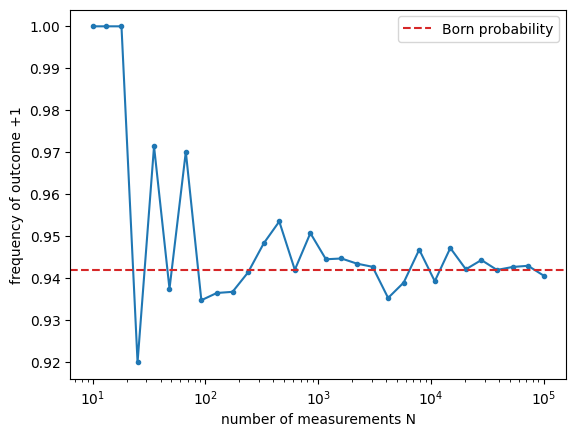

In [3]:
Ns = np.unique(np.logspace(1, 5, 30).astype(int))
freq = []
for N in Ns:
    outcomes = rng.choice(2, size=N, p=p/p.sum())
    freq.append(np.mean(outcomes == 1))
plt.semilogx(Ns, freq, 'o-', ms=3); plt.axhline(p[1], color='C3', ls='--', label="Born probability")
plt.xlabel("number of measurements N"); plt.ylabel("frequency of outcome +1"); plt.legend(); plt.show()

## Indeterminacy (Robertson)

In [4]:
def mean(A): return np.real(psi.conj() @ A @ psi)
def dev(A): return np.sqrt(mean(A @ A) - mean(A)**2)
lhs = dev(sx) * dev(sy); rhs = abs(mean(sz))
print("Δσx·Δσy =", lhs, " >= |<σz>| =", rhs, "→ holds", lhs >= rhs - 1e-12)
# equality for a σz eigenstate? (ΔσxΔσy = 1 = |<σz>|)
psi = np.array([1, 0], dtype=complex); print(dev(sx)*dev(sy), abs(mean(sz)))

Δσx·Δσy = 0.6169910161759725  >= |<σz>| = 0.5403023058681398 → holds True
1.0 1.0
